# Поиска инсайтов и точек роста

Будем работать с данными сервиса доставки еды.

Заказчик просит найти инсайты, которые позволят сервису повысить показатель удержания пользователей и улучшить взаимодействие с партнёрами, а так же ответить на вопросы:
- Как ведут себя пользователи? Как наиболее эффективно выстроить работу с ними, чтобы они продолжали пользоваться продуктом?
- Какой путь проходят пользователи в сервисе? Где «проваливаются»?
- Как улучшить взаимодействие с партнёрами-ресторанами?

#### Задачи 

В рамках проекта проведём комплексный анализ данных:
- изучим пользовательский путь и проанализируем конверсии через воронки;
- сегментируем пользователей с помощью RFM-модели для оценки лояльности и поведения клиентов;
- кластеризуем рестораны методом K-Means, чтобы выделить группы с разными моделями работы и разработать персонализированные маркетинговые стратегии.

Такой подход позволит ближе познакомиться с работой сервиса, выявить узкие места и предложить решения для удержания пользователей и повышения эффективности сотрудничества с ресторанами.


#### Данные

Данные включают следующие сведения:
      
- `visitor_uuid` — идентификатор посетителя. Это идентификатор, который присваивается системой любому новому пользователю вне зависимости от того, зарегистрировался он в продукте или нет.
- `user_id` — идентификатор зарегистрированного пользователя. Присваивается посетителю после создания учётной записи: ввода логина, пароля, адреса доставки и контактных данных.
- `device_type` — тип платформы, с которой посетитель зашёл в продукт.
- `city_id` — город, из которого посетитель зашёл в сервис.
- `source` — рекламный источник привлечения посетителя.
- `first_date` — дата первого посещения продукта.
- `visit_id` — уникальный идентификатор сессии.
- `event` — название аналитического события.
- `datetime` — дата и время события.
- `rest_id` — уникальный идентификатор ресторана (заполняется для заказов, карточек ресторанов и блюд).
- `object_id` — уникальный идентификатор блюда (заполняется для заказов и карточек блюд).
- `order_id` — уникальный идентификатор заказа.
- `revenue` — выручка от заказа (в рублях). Это та сумма, которую пользователь видит при оплате.
- `delivery` — стоимость доставки (в рублях).
- `commission` — комиссия, которую сервис берёт с выручки ресторана, в процентах.

    
#### План проекта
- Загрузка данных и их предобработка.
- Анализ пользовательского пути новых пользователей.
- RFM сегментация.
- K-Means кластеризация.
- Итоговый вывод и рекомендации.

## 1. Загрузка данных и их предобработка

#### Загружаем необходимые для работы библиотеки в отдельной ячейке:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D

#### Загружаем датасет, сразу форматируем столбцы с датой в формат "datetime" и выводим общую информацию:

In [2]:
print(f"Размер датасета: {df.shape}")
display(df.isnull().sum().to_frame(name='Пропуски'))
display(df.dtypes.to_frame(name='Тип данных'))
print("\nПолные дубликаты строк:", df.duplicated().sum())
display(df.head())

Размер датасета: (205510, 15)


,Пропуски
visitor_uuid,0
user_id,0
device_type,0
city_id,0
source,0
first_date,0
visit_id,0
event,0
datetime,0
rest_id,38595


,Тип данных
visitor_uuid,str
user_id,float64
device_type,str
city_id,int64
source,str
first_date,datetime64[us]
visit_id,int64
event,str
datetime,datetime64[us]
rest_id,str



Полные дубликаты строк: 0


,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,authorization,2021-05-01 16:07:53,NaN,NaN,NaN,NaN,NaN,NaN
1,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,reg_page,2021-05-01 16:09:16,NaN,NaN,NaN,NaN,NaN,NaN
2,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,confirm_phone,2021-05-01 16:09:19,NaN,NaN,NaN,NaN,NaN,NaN
3,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,login,2021-05-01 16:09:23,NaN,NaN,NaN,NaN,NaN,NaN
4,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,main_page,2021-05-01 16:09:34,2c6095730b514c189ee41c65f03febc3,NaN,NaN,NaN,NaN,NaN


#### Проверка неявных дубликатов:

In [3]:
implicit_duplicates = df.duplicated(subset=['user_id', 'datetime', 'event']).sum()
print(f"Неявных дубликатов: {implicit_duplicates}")
rows_before = len(df)
print(f"Строк до удаления дубликатов: {rows_before}")
df = df.drop_duplicates(subset=['user_id', 'datetime', 'event'], keep='first')
rows_after = len(df)
print(f"Строк после удаления дубликатов: {rows_after}")
removed = rows_before - rows_after
print(f"Удалено строк: {removed}")

Неявных дубликатов: 7
Строк до удаления дубликатов: 205510
Строк после удаления дубликатов: 205503
Удалено строк: 7


#### Оценка объема данных и периода:

In [4]:
print(f"Период данных: с {df['datetime'].min().date()} по {df['datetime'].max().date()}")
print(f"Уникальных посетителей: {df['visitor_uuid'].nunique()}")
print(f"Уникальных ресторанов: {df['rest_id'].nunique()}")

Период данных: с 2021-05-01 по 2021-07-02
Уникальных посетителей: 8891
Уникальных ресторанов: 21


Данные загружены. Колонки с датами мы сразу же при загрузке датасета перевели в формат `datetime64[ns]` для удобства дальнейшего анализа. Нашли и удалили 7 неявных дубликатов по ключевым полям. Осталось 205 503 записи. Пропуски в колонках с заказами ожидаемы и не требуют обработки. Период данных с 1 мая по 2 июля 2021 года. У нас 8891 уникальный посетитель и 21 ресторан. Данные готовы, переходим к анализу пользовательского пути.

---

## 2. Анализ пользовательского пути

Маркетологи стали замечать следующее: деньги на рекламу по-прежнему тратятся, а заказов стало меньше. И это несмотря на то, что приложение скачивается и устанавливается так же активно, как раньше. Складывается ощущение, что пользователи где-то теряются. При этом доля заказов с десктопной версии приложения увеличилась по сравнению с мобильной.

Разработчики говорят, что последние обновления мобильной версии приложения не должны были повлиять на каталог блюд или его выбор для заказа и последующей оплаты доставки, так как изменения касались нового алгоритма подтверждения мобильного телефона и адреса доставки.

С помощью воронок изучим общий пользовательский путь новых пользователей, затем сравним поведение пользователей мобильной и десктопной версий приложения. 

Предполагается, что пользователь проходит такой путь к оформлению доставки блюда из ресторанов:
1. `authorization` — авторизация пользователя — запуск приложения.
2. `main_page` — загрузка основной страницы приложения.
2. `reg_page` — переход на страницу регистрации.
2. `confirm_phone` — подтверждение телефона (окончание процесса регистрации).
2. `object_page` — страница блюда.
2. `add_to_cart` — переход в корзину.
2. `order` — оформление заказа.    

#### Для начала нам нужно выписать все этапы воронки в нужном порядке:

In [5]:
events_order = [
    'authorization', 
    'main_page', 
    'reg_page', 
    'confirm_phone', 
    'object_page', 
    'add_to_cart', 
    'order']

#### Высчитаем количество уникальных пользователей на каждом из этапов:

In [6]:
funnel_all = df[df['event'].isin(events_order)].groupby('event')['visitor_uuid'].nunique().reindex(events_order).reset_index()
funnel_all.columns = ['event', 'users']
display(funnel_all)

,event,users
0,authorization,7796
1,main_page,6835
2,reg_page,5649
3,confirm_phone,4347
4,object_page,3530
5,add_to_cart,2929
6,order,2432


#### Теперь мы можем высчитать долю от первого шага и доли от предыдущих этапов. Это понадобится нам для построения воронок конверсий:

In [7]:
funnel_all['classic'] = (funnel_all['users'] / funnel_all['users'].iloc[0] * 100).round(2)
funnel_all['step_by_step'] = (funnel_all['users'] / funnel_all['users'].shift(1) * 100).fillna(100).round(2)
display(funnel_all)

,event,users,classic,step_by_step
0,authorization,7796,100.00,100.00
1,main_page,6835,87.67,87.67
2,reg_page,5649,72.46,82.65
3,confirm_phone,4347,55.76,76.95
4,object_page,3530,45.28,81.21
5,add_to_cart,2929,37.57,82.97
6,order,2432,31.20,83.03


#### Построим визуализации для наших данных:

C:\Users\Remis Piane\AppData\Local\Temp\ipykernel_16884\2379567721.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x='event', y='classic', data=funnel_all, ax=axes[0], palette='Greens_d')
C:\Users\Remis Piane\AppData\Local\Temp\ipykernel_16884\2379567721.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x='event', y='step_by_step', data=step_by_step_df, ax=axes[1], palette='Blues_d')


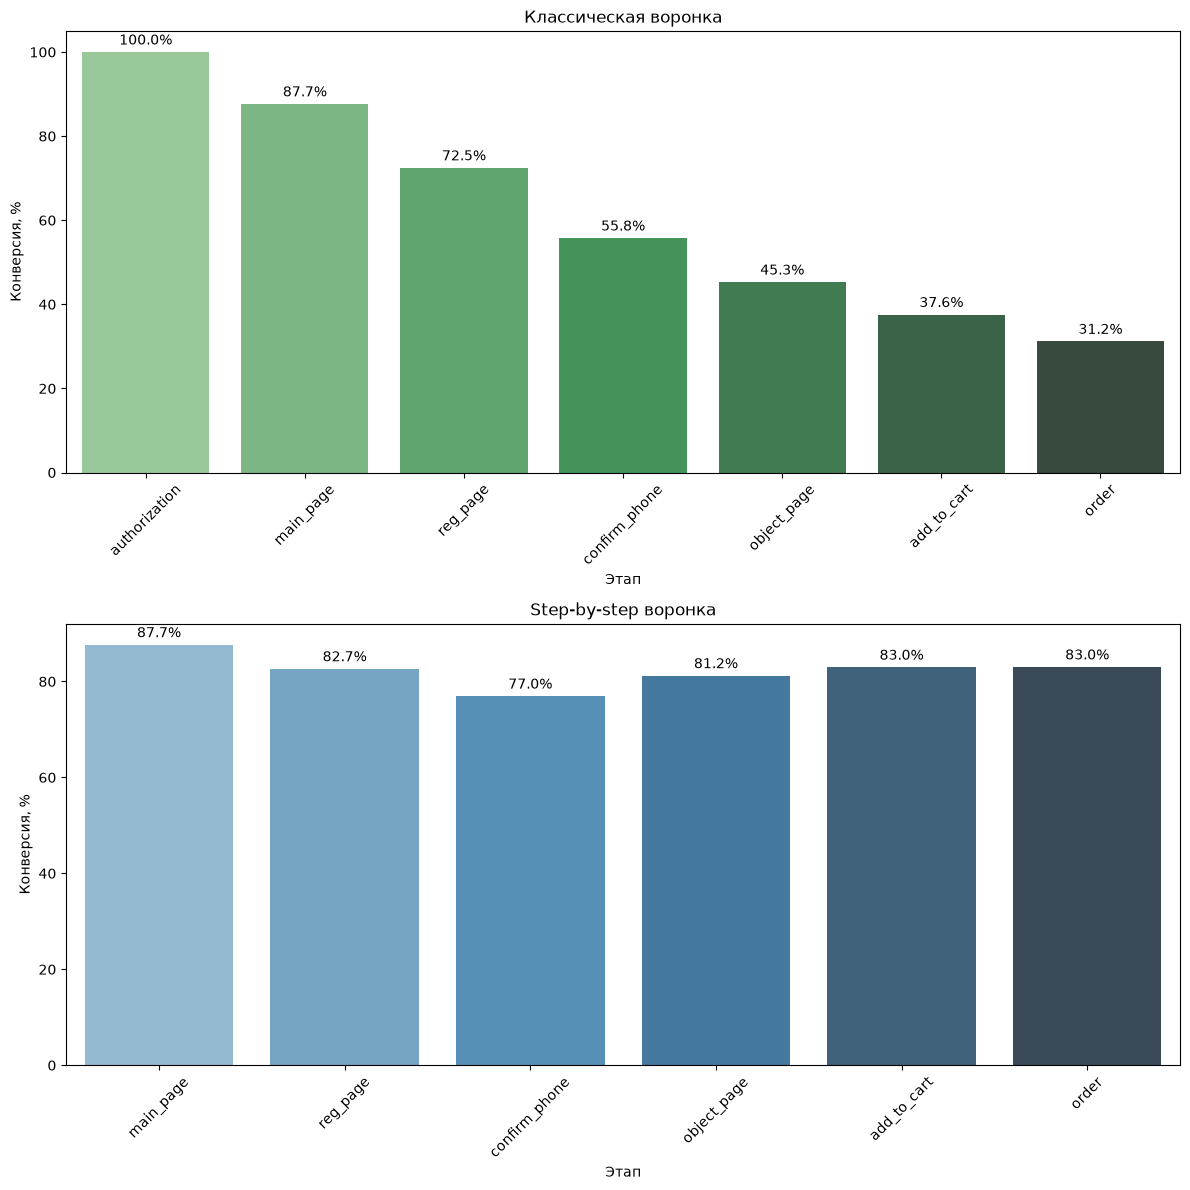

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

def add_labels(ax):
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom',
                    xytext=(0, 3), textcoords='offset points')

ax1 = sns.barplot(x='event', y='classic', data=funnel_all, ax=axes[0], palette='Greens_d')
axes[0].set_title('Классическая воронка')
axes[0].set_ylabel('Конверсия, %')
axes[0].set_xlabel('Этап')
axes[0].tick_params(axis='x', rotation=45)
add_labels(ax1)

step_by_step_df = funnel_all[funnel_all['event'] != 'authorization']
ax2 = sns.barplot(x='event', y='step_by_step', data=step_by_step_df, ax=axes[1], palette='Blues_d')
axes[1].set_title('Step-by-step воронка')
axes[1].set_ylabel('Конверсия, %')
axes[1].set_xlabel('Этап')
axes[1].tick_params(axis='x', rotation=45)
add_labels(ax2)

plt.tight_layout()
plt.show()

**Вывод:** 

Построили две воронки для всего потока новых пользователей. Классическая показывает, что от первого шага до заказа доходит 31% пользователей. Step-by-step даёт более детальную картину.

Самая проблемная точка - этап подтверждения телефона. На нём теряется почти четверть пользователей, которые дошли до регистрации. Конверсия с регистрации на подтверждение телефона падает до 77%. Это самый сильный провал во всей воронке.

Дальше, от просмотра блюда до оформления заказа, конверсия держится стабильно выше 80% на каждом шаге. Значит, проблема не в каталоге и не в корзине, а именно в процессе подтверждения телефона.

Остальные этапы работают нормально. Основные потери происходят на ранних шагах, но ключевой барьер - подтверждение телефона. Именно на него стоит обратить внимание в первую очередь.

### Сравним пользовательский путь в двух приложениях: в мобильной версии и десктопной.

#### Для сравнения пользовательского пути мобильной и десктопной версии приложений нам необходимо отфильтровать и агрегировать данные для каждой из версий:

In [9]:
#Desktop
desktop_funnel = df[(df['event'].isin(events_order)) & (df['device_type'] == 'Desktop')] \
    .groupby('event')['visitor_uuid'].nunique().reindex(events_order).reset_index()
desktop_funnel['desktop_step'] = (desktop_funnel['visitor_uuid'] / desktop_funnel['visitor_uuid'].shift(1) * 100).fillna(100).round(2)

#Mobile
mobile_funnel = df[(df['event'].isin(events_order)) & (df['device_type'] == 'Mobile')] \
    .groupby('event')['visitor_uuid'].nunique().reindex(events_order).reset_index()
mobile_funnel['mobile_step'] = (mobile_funnel['visitor_uuid'] / mobile_funnel['visitor_uuid'].shift(1) * 100).fillna(100).round(2)

#### Собираем общий датафрейм для графика:

In [10]:
compare_funnel = pd.DataFrame({
    'event': events_order,
    'desktop': desktop_funnel['desktop_step'],
    'mobile': mobile_funnel['mobile_step']
})

#### Сделаем визуализацию сравнения пошаговой конверсии Desktop и Mobile версий:

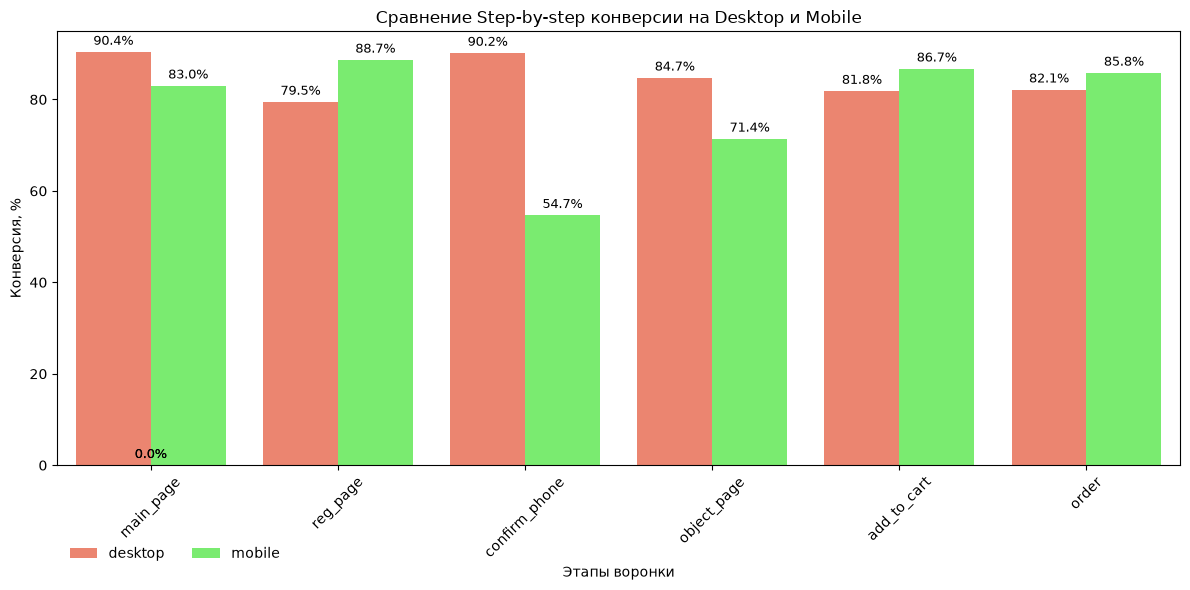

In [11]:
plot_data = compare_funnel.query("event != 'authorization'").melt(
    id_vars='event',
    var_name='Platform',
    value_name='Conversion_%'
)

plt.figure(figsize=(12, 6))
ax3 = sns.barplot(
    data=plot_data,
    x='event',
    y='Conversion_%',
    hue='Platform',
    palette=['#FF775C', '#69FF5C']
)

ax3.set(
    title='Сравнение Step-by-step конверсии на Desktop и Mobile',
    xlabel='Этапы воронки',
    ylabel='Конверсия, %'
)
plt.xticks(rotation=45)

for p in ax3.patches:
    ax3.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 3),
        textcoords='offset points'
    )
    ax3.legend(
    loc="lower left",
    bbox_to_anchor=(0, -0.25),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

**Вывод:**

Сравнение step-by-step воронок показало явное различие. На десктопе подтверждение телефона проходят 90% пользователей, а на мобильных - только около 55%. Это заметный провал.

Однако на финальных этапах картина меняется. При переходе в корзину и оформлении заказа Mobile показывает конверсию выше, чем Desktop. Это значит, что у десктопной версии есть своя зона роста и пользователи там теряются именно на этапах добавления в корзину и оплаты.

В итоге проблема на мобильных устройствах подтверждается и связана она с новым алгоритмом. При этом десктопная версия тоже работает не идеально, особенно на завершающих этапах воронки. Нужно разбираться с подтверждением телефона на смартфонах, но при этом не забывать про оптимизацию процесса оформления заказа на компьютерах.

---

## 3. RFM сегментация

У сервиса доставки еды не такое высокое удержание пользователей: в первый день возвращается около 14% посетителей, а на седьмой день — около 4–5%. 
Маркетологи хотят запустить несколько рекламных кампаний, направленных на удержание платящих пользователей и их возврат в сервис, если они давно не совершали заказы.

Для этого сегментируем пользователей на различные поведенческие сегменты с помощью RFM-сегментации по трём показателям: 
- **давность** (Recency), 
- **частота покупок** (Frequency), 
- **сумма трат** (Monetary).

В качестве даты анализа установим **03 июля 2021 года**.

#### Установим дату анализа 03.07.2021 и отберём только заказы с выручкой:

In [12]:
analysis_date = pd.to_datetime('2021-07-03')
orders = df[df['event'] == 'order'].dropna(subset=['revenue'])

#### Проведём группировку RFM по пользователям:

In [13]:
rfm = orders.groupby('visitor_uuid').agg(
    R=('datetime', lambda x: (analysis_date - x.max()).days),
    F=('order_id', 'nunique'),
    M=('revenue', 'sum')
).reset_index()

#### Визуализируем распределения R, F, M:

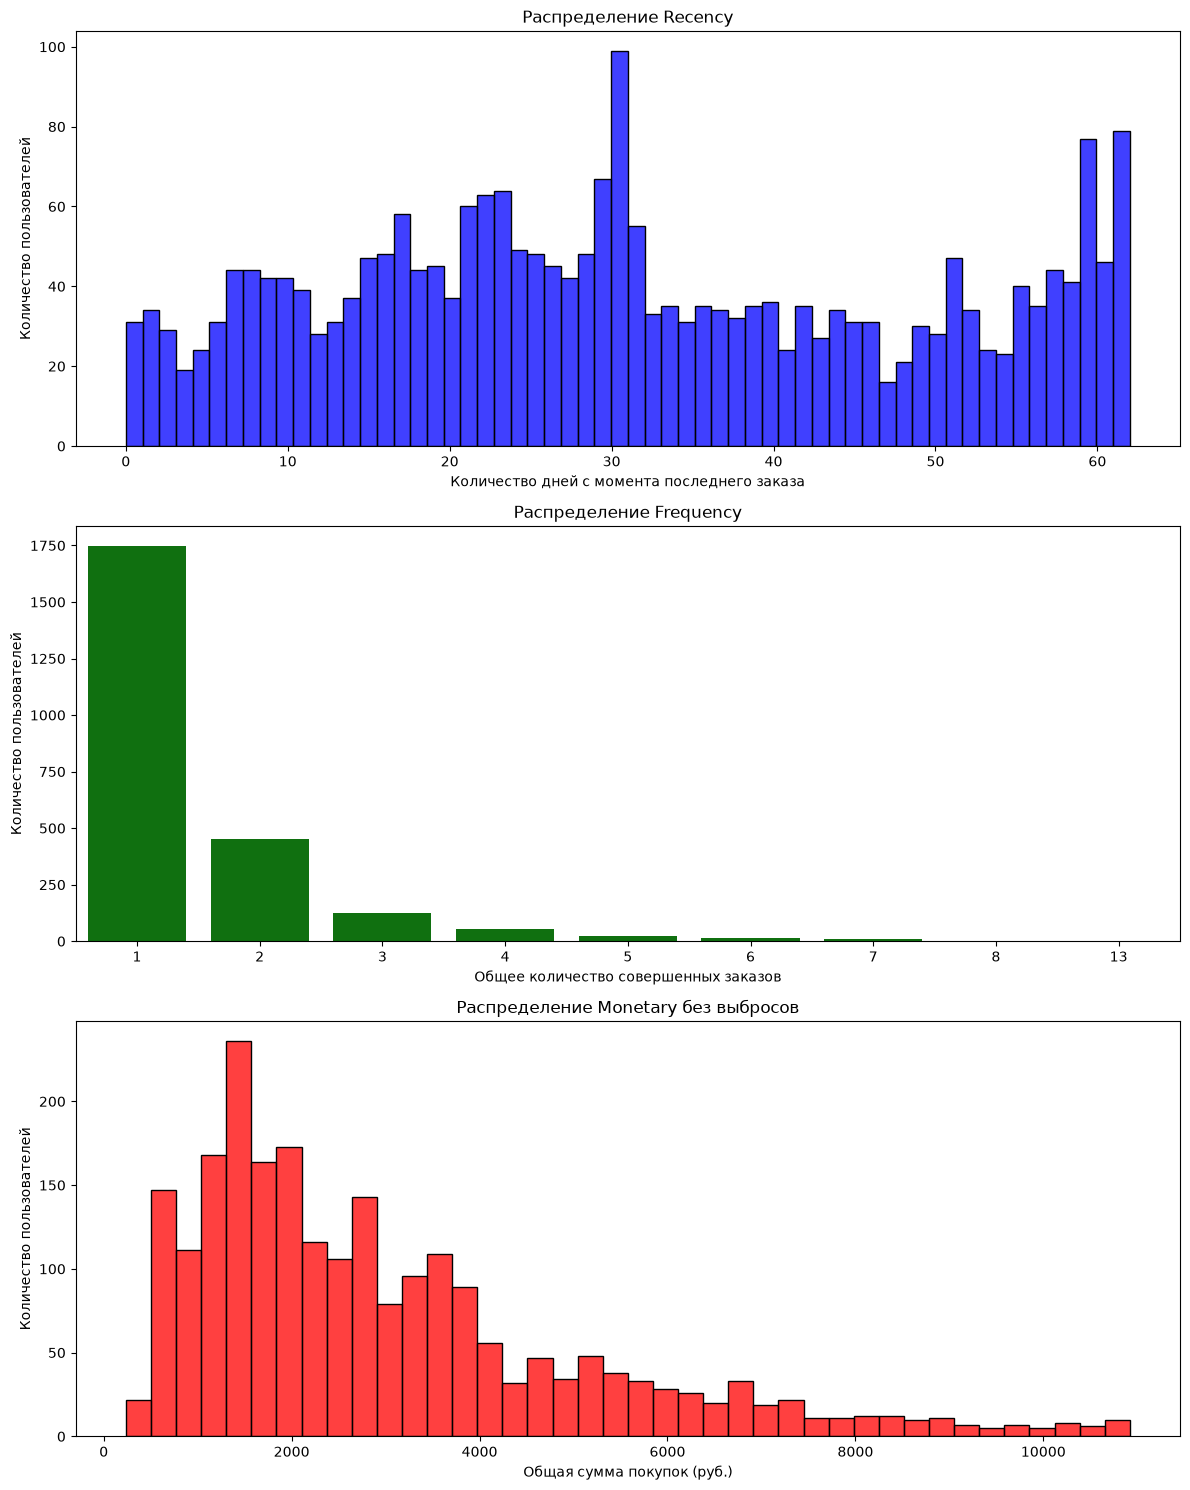

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

sns.histplot(rfm['R'], bins=60, ax=axes[0], color='blue')
axes[0].set_title('Распределение Recency')
axes[0].set_xlabel('Количество дней с момента последнего заказа')
axes[0].set_ylabel('Количество пользователей')

sns.countplot(x=rfm['F'], ax=axes[1], color='green')
axes[1].set_title('Распределение Frequency')
axes[1].set_xlabel('Общее количество совершенных заказов')
axes[1].set_ylabel('Количество пользователей')

m_limit = rfm['M'].quantile(0.95)
sns.histplot(rfm[rfm['M'] <= m_limit]['M'], bins=40, ax=axes[2], color='red')
axes[2].set_title('Распределение Monetary без выбросов')
axes[2].set_xlabel('Общая сумма покупок (руб.)')
axes[2].set_ylabel('Количество пользователей')

plt.tight_layout()
plt.show()

**Вывод:**

По давности видно, что пользователи распределены неравномерно. Есть пики на 30 и 60 днях. Значительная часть клиентов не возвращалась в сервис уже месяц или два. Таких пользователей много и их обязательно нужно возвращать.

По частоте ситуация плохая. Львиная доля покупателей совершила всего один заказ. Повторные покупки встречаются крайне редко. Это говорит о том, что удержание практически отсутствует.

По сумме трат распределение сильно скошено влево. Большинство пользователей тратят небольшие суммы, до 5-10 тысяч рублей. Крупные чеки встречаются редко.

В целом RFM-метрики показывают главную проблему сервиса. Пользователи делают один заказ и уходят. Удержание и возврат клиентов должны стать приоритетом для маркетинга.

### Выделим **RFM-сегменты** и изучим распределение пользователей по ним.
    
Применим следующие подходы к выделению RFM сегментов:
- **Recency** — разделим на три равные группы.
- **Frequency** —  разделим на три группы: 
    - пользователи с 1 заказом;
    - пользователи с 2 заказами;
    - пользователи с 3 и более заказами.
- **Monetary** — разделим на три группы по 33-му и 66-му перцентилям.

#### Разделим Recency на три равные группы:

In [15]:
rfm['R_score'] = pd.cut(rfm['R'], bins=3, labels=['3', '2', '1'])
display(rfm.groupby('R_score')['R'].agg(['min', 'max']))
print((rfm['R'].max() - rfm['R'].min()) / 3)

,min,max
R_score,,
3,0,20
2,21,41
1,42,62


20.666666666666668


#### Разделим Frequency:

In [16]:
def f_score(x):
    if x == 1: return '1'
    elif x == 2: return '2'
    else: return '3'
rfm['F_score'] = rfm['F'].apply(f_score)

#### Разделим Monetary на три группы по 33-му и 66-му перцентилям:

In [17]:
m_labels = pd.qcut(rfm['M'], q=[0, 0.33, 0.66, 1], labels=['1', '2', '3'])
rfm['M_score'] = m_labels

#### Сформируем итоговый RFM-код клиента:

In [19]:
rfm['RFM_Segment'] = rfm['R_score'].astype(str) + rfm['F_score'] + rfm['M_score'].astype(str)

#### Посчитаем количество покупателей в каждом сегменте и визуализируем наши расчёты:

C:\Users\Remis Piane\AppData\Local\Temp\ipykernel_16884\651640177.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_segments, x='RFM_Segment', y='Count', palette='crest')


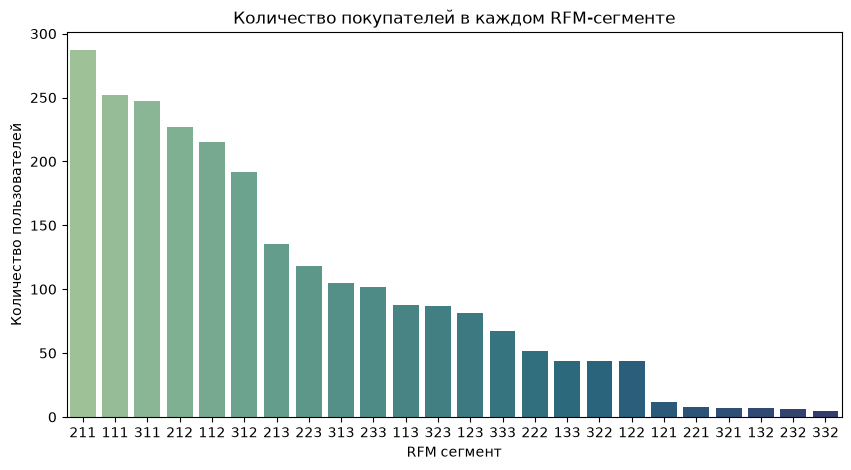

In [20]:
top_segments = rfm['RFM_Segment'].value_counts().reset_index()
top_segments.columns = ['RFM_Segment', 'Count']

plt.figure(figsize=(10, 5))
sns.barplot(data=top_segments, x='RFM_Segment', y='Count', palette='crest')
plt.title('Количество покупателей в каждом RFM-сегменте')
plt.ylabel('Количество пользователей')
plt.xlabel('RFM сегмент')
plt.show()

**Вывод:**

- Самая крупная группа на графике - сегмент 211. Это пользователи со средней давностью, одним заказом и низким чеком. На втором месте сегмент 111, который отличается более высокой давностью, то есть они ушли давно. Третьим идет сегмент 311, это недавние одноразовые пользователи с низким чеком. Вместе они формируют ядро клиентов, которые зашли один раз и больше не вернулись. Подавляющее большинство пользователей имеют частоту F, равную единице. Повторные заказы встречаются крайне редко, и клиентов с двумя или тремя заказами очень мало.
- Если смотреть глубже, выделяется еще несколько групп. Сегменты с третьим баллом по сумме трат, например 213, 313 и 113, имеют высокий чек, но при этом не возвращаются за повторными покупками. Сегменты со средним чеком 312 и 212 тоже попадают в эту категорию потерянных клиентов, но они менее прибыльны.
- Самых лояльных пользователей, которые делали более двух заказов и имеют высокую сумму трат, единицы. Это сегменты 233, 323 и 333. Они являются костяком постоянной аудитории, но их очень мало. Основная масса клиентов - это одноразовые посетители с низкой лояльностью, и сервису нужно работать именно с ними.

**Рекомендации:**

>Для массовых одноразовых сегментов с низким чеком, таких как 111, 211 и 311, не стоит тратить большие бюджеты на возврат. Им достаточно стандартных промокодов на второй заказ. Главный упор здесь нужно сделать на стимулирование повторной покупки еще на этапе оформления первого заказа, например через бонус за регистрацию или скидку на следующую доставку при оплате сейчас.

>Для потерянных клиентов с высокими чеками из сегментов 213, 313 и 113 нужны точечные акции. Они уже доказали готовность платить, поэтому персональная скидка или закрытое предложение с ограниченным сроком с большей вероятностью их вернут. Им можно отправлять пуш уведомления с персональными рекомендациями блюд.

>Группа пользователей, которые сделали недавний первый заказ и имеют средний чек, это сегменты 312 и 212. Их стоит вовлекать в регулярные рассылки с персональными подборками и небольшими бонусами за повторный заказ в ближайшую неделю. У них есть шанс перейти в постоянников.

>Для редких лояльных клиентов с высокими баллами по частоте и сумме, вроде 233, 323 и 333, нужно вводить программу лояльности с накопительными скидками или бесплатной доставкой. Это поможет удержать их и не дать уйти к конкурентам. Они формируют стабильную выручку, даже несмотря на малое количество.

---

## 4. K-Means кластеризация

Чтобы лучше понимать поведение ресторанов и предлагать им персонализированные условия сотрудничества, а также создавать персонализированные предложения для пользователей, маркетологи попросили сделать кластеризацию ресторанов по следующим параметрам:
- общее количество заказов;
- средняя стоимость заказа;
- общее число заказанных уникальных блюд (ассортимент ресторана).

С помощью метода K-Means мы разделим рестораны на кластеры, отражающие различные модели работы и целевые сегменты. Это позволяет выделить группы ресторанов с похожими характеристиками и разрабатывать для них эффективные маркетинговые стратегии.

#### Посчитаем общее количество уникальных заказов, среднюю стоимость заказа и уникальные блюда в разрезе ресторанов. Проведём группировку по `rest_id`:

In [21]:
rest_data = df[df['event'] == 'order'].groupby('rest_id').agg(
    orders=('order_id', 'nunique'),
    avg_revenue=('revenue', 'mean'),
    unique_dishes=('object_id', 'nunique')
).fillna(0)

display(rest_data.head())

,orders,avg_revenue,unique_dishes
rest_id,,,
1be5a933aab34fbab594bebba48e976e,144,2260.180222,28
1d6bb74687104fa1953924c9684fe624,108,2959.256481,19
2c6095730b514c189ee41c65f03febc3,8,1673.000000,4
3247a3b5f9494812a3c1a73c5b61f004,33,2777.209697,4
39b7eab4f4704ed2886fafe171489960,33,2011.269697,5


**Вывод:**

Подготовили таблицу с метриками для каждого ресторана. Посчитали общее количество заказов, среднюю стоимость заказа и число уникальных блюд в ассортименте. Уже по первым строкам видно, что рестораны сильно отличаются друг от друга. Есть заведения с сотнями заказов и высоким средним чеком, а есть небольшие точки с единичными заказами и узким меню. Все нужные признаки для кластеризации рассчитаны, пропусков нет. Можно переходить к разделению ресторанов на группы.

#### Проведём нормализацию данных чтобы все параметры влияли на кластеризацию одинаково:

In [22]:
scaler = StandardScaler()
rest_scaled = scaler.fit_transform(rest_data)

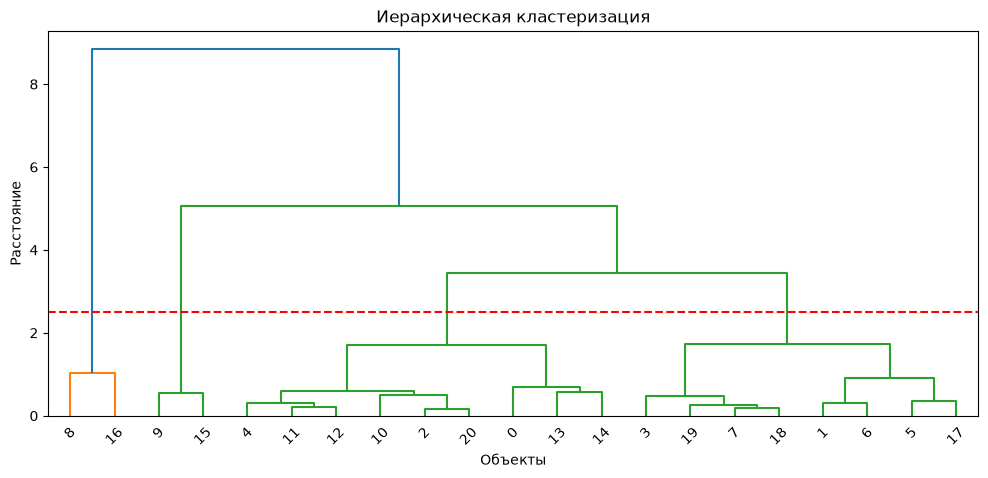

In [23]:
linked = linkage(rest_scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(linked, orientation='top')
plt.axhline(y=2.5, color='r', linestyle='--')
plt.title("Иерархическая кластеризация")
plt.xlabel("Объекты")
plt.ylabel("Расстояние")
plt.show()

#### Построим график зависимости инерции от числа кластеров метод "локтя":

C:\conda_envs\product_analytics\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
C:\conda_envs\product_analytics\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\conda_envs\product_analytics\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are

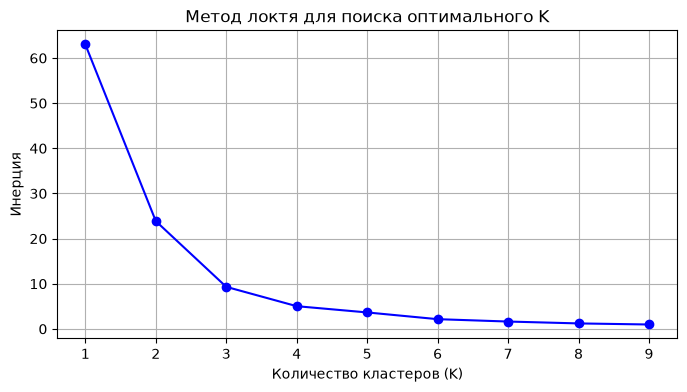

In [24]:
inertias = []
K = range(1, 10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rest_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, inertias, marker='o', linestyle='-', color='b')
plt.title('Метод локтя для поиска оптимального K')
plt.xlabel('Количество кластеров (K)')
plt.ylabel('Инерция')
plt.grid(True)
plt.show()

Нормализовали данные. График локтя показывает изгиб на трёх кластерах, но дендрограмма даёт более точную картину. Зелёный кластер внутри делится на три подгруппы, и если провести линию отсечения на уровне 2.5, получатся четыре чёткие группы. Это разделение лучше отражает различия между ресторанами. Останавливаемся на четырёх кластерах.

#### С помощью KMeans проводим кластеризацию ресторанов на 3 кластера:

In [26]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
rest_data['cluster'] = kmeans_final.fit_predict(rest_scaled)
rest_data['cluster'] = rest_data['cluster'].astype(str)
display(rest_data.head())

C:\conda_envs\product_analytics\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,orders,avg_revenue,unique_dishes,cluster
rest_id,,,,
1be5a933aab34fbab594bebba48e976e,144,2260.180222,28,0
1d6bb74687104fa1953924c9684fe624,108,2959.256481,19,2
2c6095730b514c189ee41c65f03febc3,8,1673.000000,4,0
3247a3b5f9494812a3c1a73c5b61f004,33,2777.209697,4,2
39b7eab4f4704ed2886fafe171489960,33,2011.269697,5,0


#### Рассчитаем средние метрики в кластерах ресторанов:

In [27]:
cluster_stats = rest_data.groupby('cluster').agg({
    'orders': ['mean', 'count'], 
    'avg_revenue': 'mean', 
    'unique_dishes': 'mean'
}).round(2)
display(cluster_stats)

orders       avg_revenue unique_dishes
            mean count        mean          mean
cluster                                         
0          71.73    11     1931.62          8.64
1        1100.00     2     2498.83         83.00
2          65.33     6     3024.75          9.17
3          84.00     2     4657.77          2.50

#### Построим визуализации:
- средний чек в зависимости от количества заказов
- количество блюд в зависимости от количества заказов

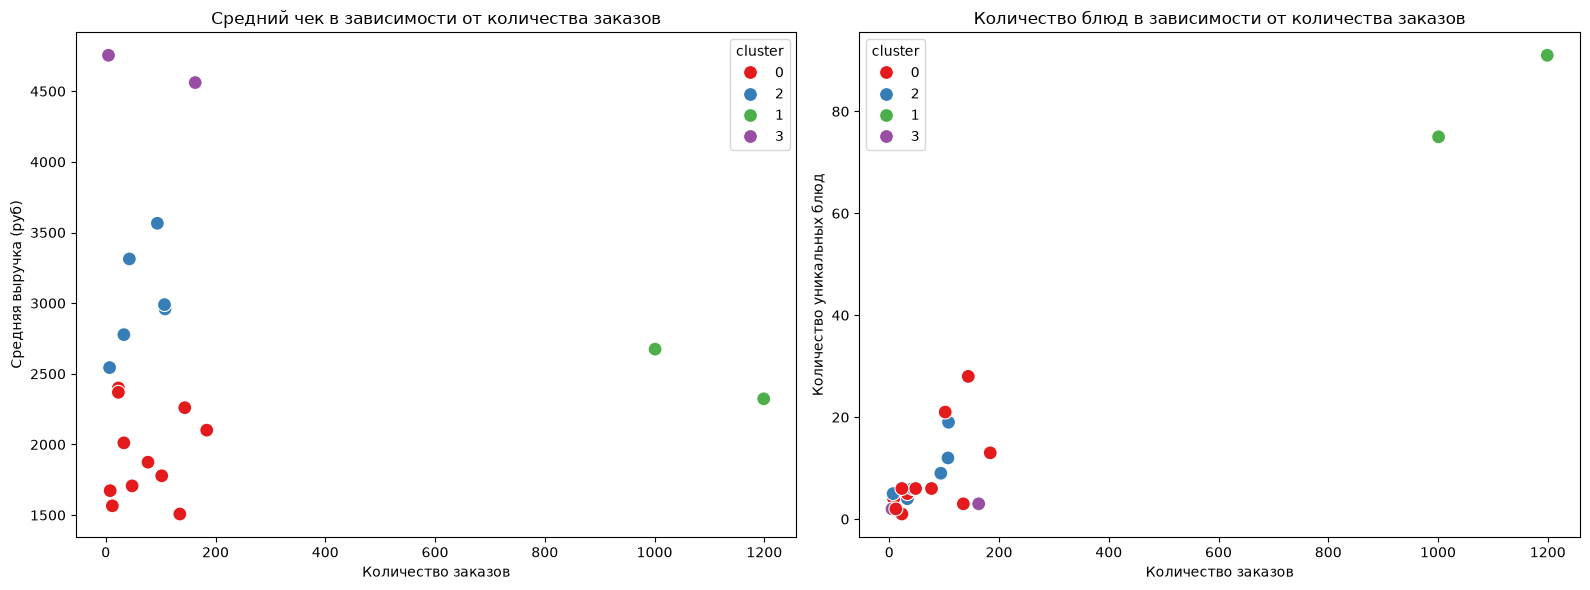

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=rest_data, x='orders', y='avg_revenue', hue='cluster', palette='Set1', s=100, ax=axes[0])
axes[0].set_title('Средний чек в зависимости от количества заказов')
axes[0].set_xlabel('Количество заказов')
axes[0].set_ylabel('Средняя выручка (руб)')

sns.scatterplot(data=rest_data, x='orders', y='unique_dishes', hue='cluster', palette='Set1', s=100, ax=axes[1])
axes[1].set_title('Количество блюд в зависимости от количества заказов')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество уникальных блюд')

plt.tight_layout()
plt.show()

#### Также построим 3D визуализацию для наглядности:

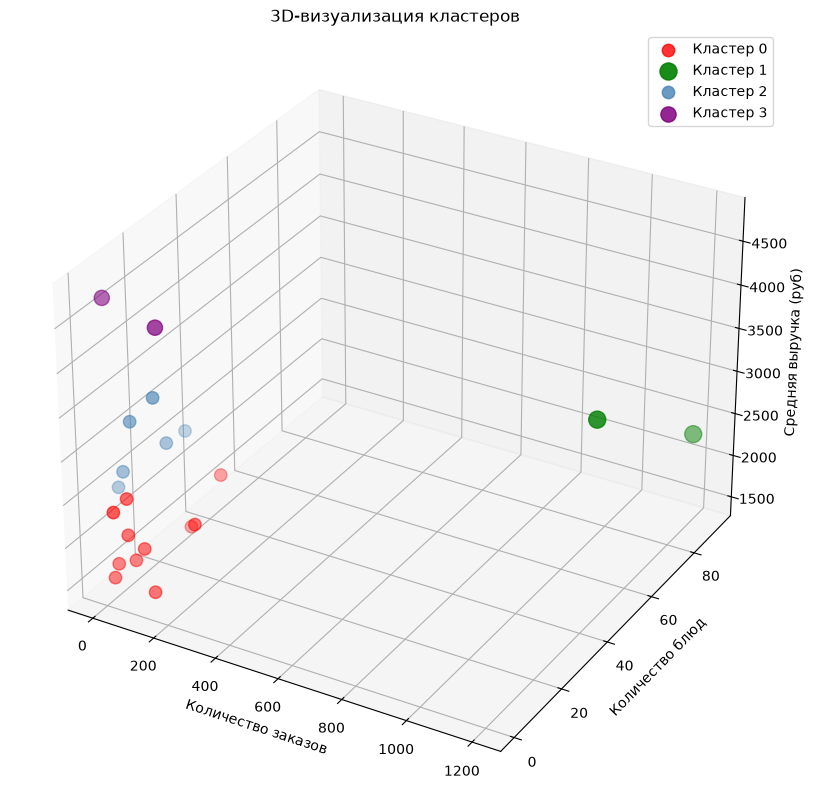

In [29]:
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

cluster_0 = rest_data[rest_data['cluster'] == '0']
cluster_1 = rest_data[rest_data['cluster'] == '1']
cluster_2 = rest_data[rest_data['cluster'] == '2']
cluster_3 = rest_data[rest_data['cluster'] == '3']

ax.scatter(
    cluster_0['orders'], cluster_0['unique_dishes'], cluster_0['avg_revenue'],
    color='red', label='Кластер 0', s=80, alpha=0.8
)
ax.scatter(
    cluster_1['orders'], cluster_1['unique_dishes'], cluster_1['avg_revenue'],
    color='green', label='Кластер 1', s=150, alpha=0.9
)
ax.scatter(
    cluster_2['orders'], cluster_2['unique_dishes'], cluster_2['avg_revenue'],
    color='steelblue', label='Кластер 2', s=80, alpha=0.8
)
ax.scatter(
    cluster_3['orders'], cluster_3['unique_dishes'], cluster_3['avg_revenue'],
    color='purple', label='Кластер 3', s=120, alpha=0.85
)

ax.set_xlabel('Количество заказов')
ax.set_ylabel('Количество блюд')
ax.set_zlabel('Средняя выручка (руб)')
ax.set_title('3D-визуализация кластеров')
ax.legend()
plt.show()

**Вывод:**

Провели кластеризацию на четыре группы. Это позволило точно разделить рестораны по их моделям работы.

Кластер 0 самый массовый. В него попало большинство ресторанов. У них в среднем 72 заказа, низкий чек около 1930 рублей и небольшой ассортимент из 9 блюд. Это массовый сегмент с невысокой маржинальностью и стандартным меню. Им нужно наращивать средний чек, и понемногу расширять ассортимент, чтобы привлечь больше клиентов.

Кластер 1 включает два ресторана-гиганта. Количество заказов у каждого переваливает за тысячу, ассортимент широкий, в среднем 83 блюда, а чек держится на уровне 2500 рублей. Эти рестораны формируют основной трафик сервиса. Им нужна стабильность работы и качество, а также программы лояльности для постоянных клиентов, чтобы удерживать поток.

Кластер 2 выделяется средним чеком в 3025 рублей при скромном количестве заказов около 65 и ассортименте из 9 блюд. Это более дорогие рестораны, но не эксклюзивные. Они находятся между массовым и премиум-сегментом. Их аудитория готова платить выше среднего, но при этом они не такие элитные, как следующий кластер. Им подойдут акции на повторные заказы и расширение меню для роста числа клиентов.

Кластер 3 это самая элитная группа. У них всего около 3 уникальных блюд в меню, но средний чек достигает 4650 рублей. Это узкоспециализированные рестораны, которые работают на небольшую, но очень платёжеспособную аудиторию. Они продают дорого и почти не расширяют ассортимент. У них должны быть персональные предложения для постоянных клиентов.

Использование четырёх кластеров вместо трёх дало более чёткое разделение премиум-сегмента. Мы увидели, что дорогие рестораны не однородны. Одни имеют высокий чек и нормальный ассортимент, другие — максимальный чек и почти пустое меню. Это даёт маркетингу возможность разрабатывать отдельные стратегии для каждой из этих бизнес-моделей, что сделает работу с партнёрами более эффективной.

---

## 5. Итоговый вывод и рекомендации

- Главная проблема сервиса находится на этапе подтверждения телефона в мобильной версии. Конверсия там падает до 55 процентов, хотя на десктопе этот же этап проходят 90 процентов пользователей. Остальная воронка, особенно после регистрации, работает стабильно. Это может указывать на технический или интерфейсный сбой в новом алгоритме на мобильных устройствах. Исправление этой точки даст быстрый прирост заказов. При этом у десктопной версии есть зона роста на этапах добавления в корзину и оплаты, на них тоже стоит обратить внимание.
- Удержание платящих пользователей остаётся слабым звеном. Большинство клиентов делают только один заказ и больше не возвращаются. 
    - RFM-анализ показал, что основная масса покупателей сосредоточена в сегментах с одним заказом, низким или средним чеком и большой давностью. Это сегменты 111, 211 и 311. Все они объединены низкой частотой и отсутствием повторных покупок. 
    - Также выделяется группа с высоким чеком и одним заказом — сегменты 312 и 313. Они уже доказали готовность платить, но не вернулись. Их нужно возвращать через персональные скидки. 
    - Для массовых одноразовых сегментов, таких как 111 и 211, лучше внедрять механизмы стимулирования второго заказа прямо во время оформления первого, например бонус или скидку на доставку. 
    - Лояльных пользователей с частотой 2 и более заказов и высокими чеками (сегменты 233 и 323) крайне мало, их нужно поддерживать отдельной программой лояльности, чтобы они не ушли к конкурентам.
- Рестораны разделились на четыре кластера. Первый это массовые точки с низким чеком, небольшим числом заказов и скромным ассортиментом. Второй это два ресторана-гиганта с огромным потоком и широким меню. Третий это рестораны со средним чеком выше среднего и нормальным ассортиментом. Четвёртый это премиальный сегмент с максимальным чеком и очень узким меню. Для каждого нужна своя стратегия. Массовым помогать с расширением меню и повышением среднего чека. Лидеров поддерживать программами лояльности и следить за качеством. Ресторанам со средним чеком предлагать акции на повторные заказы. Премиум-сегменту — эксклюзивные коллаборации и персональные предложения.

**Главные рекомендации бизнесу:**
>- Сфокусироваться на исправлении мобильного подтверждения телефона. 
>- Запустить точечные кампании по возврату клиентов из сегментов 312 и 313 с высокими чеками. 
>- Внедрить стимулы для второго заказа для массовых одноразовых сегментов. 
>- Пересмотреть условия сотрудничества с ресторанами на основе четырёх кластеров. 

Эти шаги дадут рост конверсии, улучшат удержание и сделают работу с партнёрами более эффективной.